In [1]:
import pandas as pd
df_orders = pd.read_csv("store_orders.csv")
df_customers = pd.read_csv("store_customers.csv")

In [2]:
import sqlite3
con = sqlite3.connect("store.db")
df_orders.to_sql("orders", con, index=False, if_exists="replace")
df_customers.to_sql("customers", con, index=False, if_exists="replace")

40

In [3]:
pd.read_sql("SELECT name FROM sqlite_master", con)

,name
0,orders
1,customers


In [4]:
pd.read_sql("SELECT * FROM orders LIMIT 5", con)

,order_id,customer_id,product,category,amount,order_date
0,5000,4,paper,office,14.09,2026-05-25
1,5001,15,planner,office,51.86,2026-05-08
2,5002,34,shelf,furniture,116.25,2026-06-03
3,5003,2,granola,snacks,19.72,2026-05-19
4,5004,17,monitor,electronics,284.80,2026-05-10


In [5]:
pd.read_sql("SELECT * FROM orders WHERE amount > 100 ORDER BY amount DESC", con)

,order_id,customer_id,product,category,amount,order_date
0,5153,20,dock,electronics,499.00,2026-05-25
1,5140,30,headset,electronics,295.36,2026-05-26
2,5047,901,headset,electronics,293.79,2026-05-15
3,5150,903,monitor,electronics,293.35,2026-06-06
4,5014,6,monitor,electronics,287.83,2026-05-22
...,...,...,...,...,...,...
79,5107,38,shelf,furniture,110.31,2026-05-17
80,5046,13,shelf,furniture,108.47,2026-05-28
81,5009,14,chair,furniture,107.20,2026-05-24
82,5007,36,dock,electronics,103.77,2026-05-21


In [6]:
pd.read_sql("SELECT category, COUNT(*) AS n, AVG(amount) AS avg_amount FROM orders GROUP BY category ORDER BY avg_amount DESC", con)

,category,n,avg_amount
0,electronics,60,190.569500
1,furniture,46,146.251522
2,office,51,30.132549
3,snacks,43,14.619767


The electronics category earns the most per order.

In [7]:
pd.read_sql("SELECT c.city, SUM(o.amount) AS total_spend FROM orders o JOIN customers c ON o.customer_id = c.customer_id  GROUP BY c.city ORDER BY total_spend DESC" 
, con)

,city,total_spend
0,Los Angeles,5862.99
1,Culver City,5316.88
2,Santa Monica,4017.93
3,Inglewood,2718.25
4,Torrance,1037.25
5,Venice,462.36


In [8]:
pd.read_sql("SELECT COUNT(*) AS n FROM orders", con)

,n
0,200


In [9]:
pd.read_sql("SELECT COUNT(*) AS n FROM orders o JOIN customers c ON o.customer_id = c.customer_id", con)

,n
0,195


The original rows for orders is 200 and the number of rows for the joined row counts is 195. This differnece in rows is due to 5 orders whose customer_id doesn't match a customer. Therefore when the tables were joined those 5 rows were not included in the city spending total. 

In [10]:
df_city = pd.read_sql("SELECT c.city, SUM(o.amount) AS total_spend FROM orders o JOIN customers c ON o.customer_id = c.customer_id  GROUP BY c.city ORDER BY total_spend DESC" 
, con)

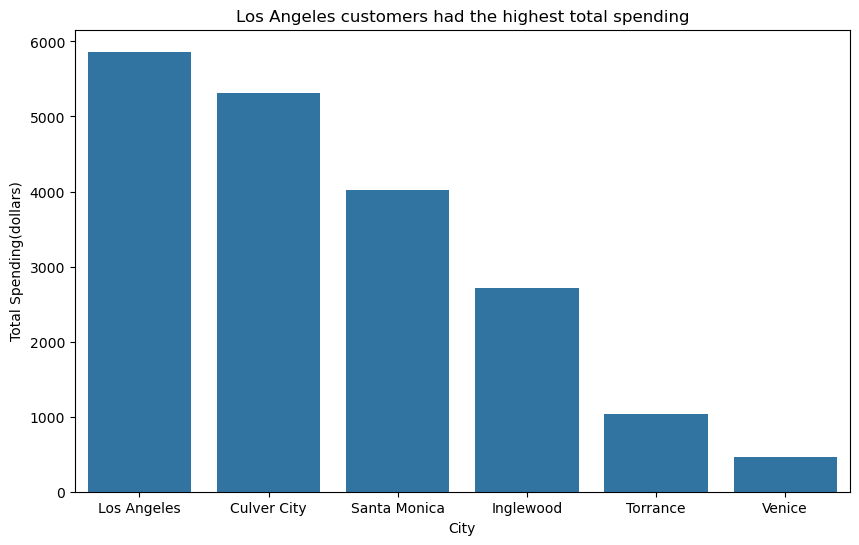

In [11]:
import seaborn as sns
import matplotlib.pyplot as plt
plt.figure(figsize=(10,6))
sns.barplot(data=df_city, x="city", y="total_spend")

plt.title("Los Angeles customers had the highest total spending")
plt.xlabel("City")
plt.ylabel("Total Spending(dollars)")
plt.show()

Business question: Which product brings in the most total revenue?

In [12]:
import pandas as pd
import sqlite3
pd.read_sql("SELECT product, SUM(amount) AS total_revenue FROM orders GROUP BY product ORDER BY total_revenue DESC", con)

,product,total_revenue
0,headset,4902.30
1,dock,3357.14
2,monitor,3174.73
3,shelf,3030.45
4,chair,2589.93
5,desk,1107.19
6,pens,597.78
7,paper,526.55
8,planner,412.43
9,granola,258.56


The product that brings in the most total revenue is the headset with $4902.30.

**Ethic Note:** Since this data set contains sensitivee data like customers name, I would strip the customer's names before sharing publcily. I would also share group toatls instead of sharing an individual customer's recordss to protect the customer's privacy.


https://github.com/jazzminowens/cs82a-portfolio